Данные о депресии студентов. 
Колонки: 
Gender	                    Пол
Age	                        Возраст
Family_background	        Обеспеченность семьи
Relationship_status	        Статус отношений
Marital_status	            Семейный статус (состоит ли в браке)
Living_style	            Образ жизни
Current_semester	        Текущий семестр
CGPA	                    Средний балл (средняя успеваемость)
friend_circle	            Круг общения / Количество друзей
Health_condition	        Состояние здоровья
Cost_without_study	        Расходы, не связанные с учёбой
Home_division	            Родной округ / область
Depression	                Депрессия
Задачи: 
    - Гендерное распределение студентов имеющих депрессию
    - Доля депрессии на каждый возраст
    - Влияние обеспеченности семьи на наличие депрессии


In [ ]:
%pip install pandas
%pip install numpy
%pip install matplotlib

Читаем csv файлы и читаем первые 5 строк, чтобы понять в каком виде данные. 

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Student_Depression_Dataset.csv")
print(df.head(5))

   Gender  Age Family_background Relationship_status Marital_status  \
0  Female   22      Middle class              Single      Unmarried   
1    Male   19      Middle class              Single      Unmarried   
2    Male   23      Middle class              Single      Unmarried   
3    Male   20      Middle class         Complicated      Unmarried   
4  Female   21      Middle class              Single      Unmarried   

  Living_style  Current_semester  CGPA friend_circle Health_condition  \
0     Bachelor                 8  3.43           Yes         Critical   
1     Bachelor                 2  3.70           Yes         Abnormal   
2       Family                 8  3.28            No         Abnormal   
3       Family                 2  3.77            No             Good   
4       Family                 1  4.00            No         Abnormal   

   Cost_without_study Home_division Depression  
0               10113    Chittagong        Yes  
1               13815    Chittagong 

Так же узнаем инфорфмацию о данных и об их типе(есть ли пропуски - NaN значения).

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB


Пропусков нет, поэтому нам не нужно заполнять их. Узнаем долю студентов имеющих депрессию c разделениями по полу.

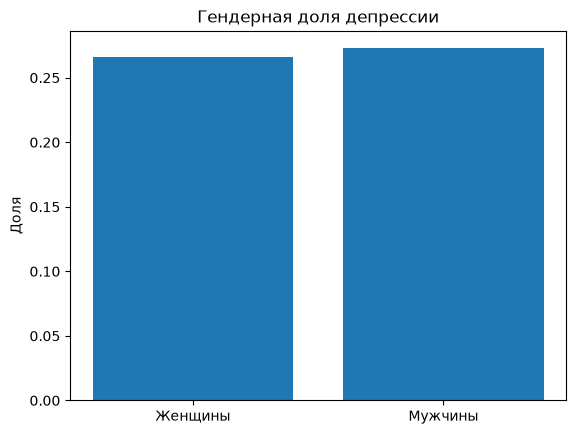

In [4]:
df["Depressed"] = (df["Depression"] == "Yes").astype(int)
depression_percent = df.groupby("Gender")["Depressed"].mean()
plt.tight_layout()
plt.bar(depression_percent.keys().map({"Female":"Женщины", "Male":"Мужчины"}), depression_percent.values)
plt.title("Гендерная доля депрессии")
plt.ylabel("Доля")
plt.savefig("graph1.png")

Как видим, примерно четветь как среди мужчин и женщин имеют депрессию, но среди мужчин доля чуть-чуть выше.
Узнаем долю депрессии на каждый возраст.

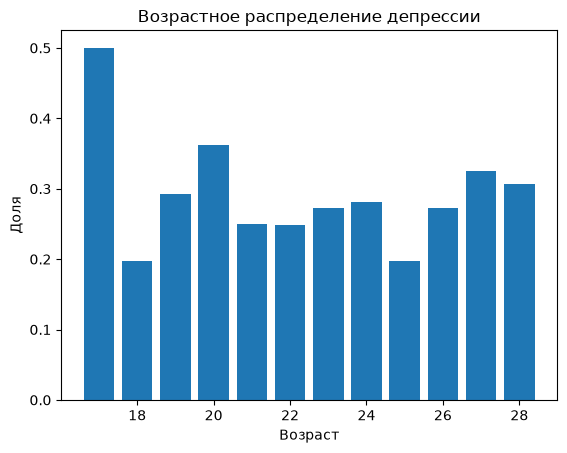

In [5]:
age_rate_depression = df.groupby("Age")["Depressed"].mean()
plt.bar(age_rate_depression.keys(), age_rate_depression)
plt.title("Возрастное распределение депрессии")
plt.xlabel("Возраст")
plt.ylabel("Доля")
plt.savefig("graph2.png")

Как видим доля депрессии колеблется от 0.2 до 0.35 в среднем на каждый возраст. Но максимальная доля приходит на 17 лет - 0.5, то есть половина студентов. Стоит отметить, что и количество студентов на каждый возраст разное, поэтому здесь могут быть шумы, поэтому точные выводы делать не стоит. Определим влияет ли обеспеченность семьи на шанс появления депрессии.

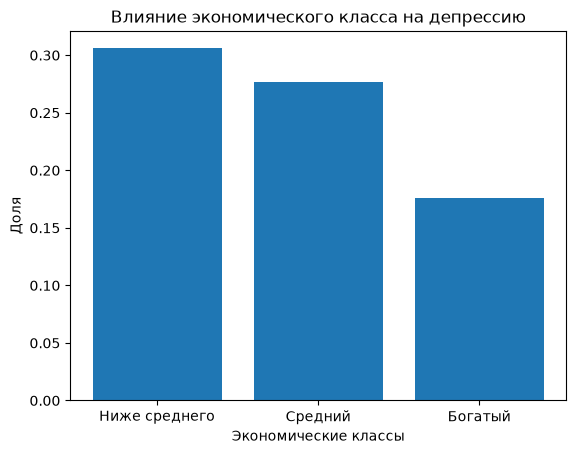

In [6]:
family_background_rate = df.groupby("Family_background")["Depressed"].mean()
plt.bar(family_background_rate.keys().map({"Lower Middle class": "Ниже среднего",
                                           "Middle class": "Средний",
                                           "Rich class": "Богатый"}), family_background_rate)
plt.title("Влияние экономического класса на депрессию")
plt.xlabel("Экономические классы")
plt.ylabel("Доля")
plt.savefig("graph3.png")

Как видим, чем богаче семья тем ниже доля студентов, которые имеют депрессию.
Исходя из исследования, можно сделать вывод, что депрессия чуть чаще встречается у мужчин. Так же чем богаче живет человек, тем меньше вероятности появления у него депрессии.